# Setup

## GPU Initialization

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")            # before torch/numpy
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

# Keras 3 runs the CNN / BiLSTM on the PyTorch backend (no TensorFlow).
# MUST be set before `import keras` anywhere in the kernel.
os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("USE_TF", "0")                            # stop transformers importing TF

import sys, subprocess, importlib.util

# torch: needs the cu130 wheel for the RTX 5070 (Blackwell / sm_120)
try:
    import torch
    assert torch.cuda.is_available() and torch.version.cuda
    print(f"OK: torch {torch.__version__} (CUDA {torch.version.cuda})")
except (ImportError, AssertionError):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade",
        "torch", "torchvision", "--index-url", "https://download.pytorch.org/whl/cu130"])
    raise SystemExit(">>> Installed torch — RESTART KERNEL, then re-run from top <<<")

# accelerate: required by HF Trainer. Install only if missing, never -U.
if importlib.util.find_spec("accelerate") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "accelerate>=1.1.0"])
    raise SystemExit(">>> Installed accelerate — RESTART KERNEL <<<")

# keras 3: pure-Python, uses the torch already installed. No TensorFlow.
if importlib.util.find_spec("keras") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "keras>=3.5"])
    raise SystemExit(">>> Installed keras — RESTART KERNEL <<<")

OK: torch 2.13.0+cu130 (CUDA 13.0)


In [2]:
import gc, torch

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

assert torch.cuda.is_available(), "CUDA not available — check Cell 1, restart kernel."
device = torch.device("cuda")

p = torch.cuda.get_device_properties(0)
print(f"{torch.__version__} | {p.name} | {p.total_memory/1e9:.1f} GB "
      f"| cap {p.major}.{p.minor} | bf16={torch.cuda.is_bf16_supported()}")

def free_gpu():
    """del the trainer/model in the notebook first, then call this."""
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    print(f"GPU allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

2.13.0+cu130 | NVIDIA GeForce RTX 5070 Laptop GPU | 8.5 GB | cap 12.0 | bf16=True


In [3]:
import keras

print("PyTorch:", torch.__version__)
print("Keras:", keras.__version__, "| backend:", keras.config.backend())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Keras uses the same CUDA device as torch. Quick proof it lands on the GPU:
_probe = keras.layers.Dense(1)
_probe.build((None, 4))
print("Keras variable device:", _probe.weights[0].value.device)

PyTorch: 2.13.0+cu130
Keras: 3.15.1 | backend: torch
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
Keras variable device: cuda:0


## Imports

In [4]:
import os
import gc
import json
import random
import re
import pickle
import joblib
import copy
from collections import Counter
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from scipy.sparse import hstack

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

# --- Keras 3 on the PyTorch backend (KERAS_BACKEND set in the GPU-init cell) ---
import keras
from keras import Sequential
from keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

assert keras.config.backend() == "torch", (
    f"Keras backend is {keras.config.backend()!r}, expected 'torch'. "
    "Set os.environ['KERAS_BACKEND']='torch' before importing keras and restart the kernel."
)

## Paths & Variables

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
keras.utils.set_random_seed(SEED)   # seeds python / numpy / torch for the keras backend

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# PATHS
# ============================================================

OUTPUT_PATH = "models"   # relative to the notebook; "/models" would write to the drive root

os.makedirs(OUTPUT_PATH, exist_ok=True)

# ============================================================
# MODEL OUTPUT LAYOUT
# models/<category>/{logreg.joblib, textcnn/, bilstm/, distilbert/}
# ============================================================

CATEGORY_NAME = "inappropriate"

CATEGORY_DIR = f"{OUTPUT_PATH}/{CATEGORY_NAME}"
TEXTCNN_DIR = f"{CATEGORY_DIR}/textcnn"
BILSTM_DIR = f"{CATEGORY_DIR}/bilstm"
DISTILBERT_DIR = f"{CATEGORY_DIR}/distilbert"

for _dir in (CATEGORY_DIR, TEXTCNN_DIR, BILSTM_DIR, DISTILBERT_DIR):
    os.makedirs(_dir, exist_ok=True)

LABELS = ["not_inappropriate", "inappropriate"]

with open(f"{CATEGORY_DIR}/labels.json", "w") as f:
    json.dump(LABELS, f, indent=2)

# ============================================================
# TRAINING FILES
# ============================================================

INAPPROPRIATE_TRAIN_PATH = "train/inappropriate_train.csv"

# ============================================================
# FINAL TEST FILES
# DO NOT USE DURING MODEL DEVELOPMENT
# ============================================================

# INAPPROPRIATE_TEST_PATH = "test/inappropriate_test.csv"
INAPPROPRIATE_TEST_PATH = "test/inappropriate_private_test.csv"

# ============================================================
# TRANSFORMER SETTINGS
# ============================================================

DISTILBERT_NAME = "distilbert-base-uncased"

MAX_LENGTH = 128

TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

NUM_EPOCHS = 3
LEARNING_RATE = 2e-5

# ============================================================
# NEURAL NETWORK SETTINGS
# ============================================================

VOCAB_SIZE = 30000
SEQUENCE_LENGTH = 128
EMBEDDING_DIM = 128

# ============================================================
# DATASET EXPERIMENT SETTINGS
# ============================================================

INAPPROPRIATE_TARGET_SIZE = 50000

# ============================================================
# BAGGING
# Start small first.
#
# Later compare:
# 1, 3, 5, 10, 15
# ============================================================

N_BAGS = 3

# Data Preprocessing

## Load Datasets

In [6]:
inappropriate_raw = pd.read_csv(INAPPROPRIATE_TRAIN_PATH)
inappropriate_test_raw = pd.read_csv(INAPPROPRIATE_TEST_PATH)

print("Inappropriate Train:", inappropriate_raw.shape)
print("Inappropriate Test:", inappropriate_test_raw.shape)

display(inappropriate_raw.head())
display(inappropriate_test_raw.head())

Inappropriate Train: (1804874, 45)
Inappropriate Test: (97320, 45)


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,...,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59848,0.000000,"This is so cool. It's like, 'would you want yo...",0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
1,59849,0.000000,Thank you!! This would make my life a lot less...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
2,59852,0.000000,This is such an urgent design problem; kudos t...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
3,59855,0.000000,Is this something I'll be able to install on m...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,...,2006,rejected,0,0,0,0,0,0.0,0,4
4,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.0,0.021277,0.87234,0.0,0.0,0.0,...,2006,rejected,0,0,0,1,0,0.0,4,47


,id,comment_text,created_date,publication_id,parent_id,article_id,rating,funny,wow,sad,...,other_religion,black,white,asian,latino,other_race_or_ethnicity,physical_disability,intellectual_or_learning_disability,psychiatric_or_mental_illness,other_disability
0,7097320,[ Integrity means that you pay your debts.]\n\...,2017-09-13 20:12:01.484121+00,21,5945023.0,376974,approved,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7097321,This is malfeasance by the Administrator and t...,2017-05-17 07:01:51.902566+00,55,NaN,335003,approved,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,7097322,@Rmiller101 - Spoken like a true elitist. But ...,2016-12-02 17:12:12.920957+00,54,649389.0,154126,approved,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,7097323,"Paul: Thank you for your kind words. I do, in...",2017-04-21 14:58:05.474657+00,13,5158666.0,328376,approved,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7097324,Sorry you missed high school. Eisenhower sent ...,2017-10-01 19:43:12.373229+00,102,6061626.0,383983,approved,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
def clean_text_dataframe(df):
    df = df.copy()

    df["text"] = (
        df["text"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[df["text"] != ""]

    df = df.drop_duplicates(subset=["text"])

    return df.reset_index(drop=True)

## Prepare Inappropriate Train Dataset

In [8]:
INAPP_LABEL_THRESHOLD = 0.5

def prepare_inappropriate(df):

    df = df.copy()

    df["text"] = (
        df["comment_text"]
        .fillna("")
        .astype(str)
    )

    for column in ["obscene", "sexual_explicit"]:
        df[column] = pd.to_numeric(
            df[column], errors="coerce"
        ).fillna(0)

    df["label"] = (
        (df["obscene"] >= INAPP_LABEL_THRESHOLD) | (df["sexual_explicit"] >= INAPP_LABEL_THRESHOLD)
    ).astype(int)

    df["source"] = "jigsaw_inappropriate"

    return clean_text_dataframe(df[["text", "label", "source"]])

inappropriate = prepare_inappropriate(inappropriate_raw)

print(inappropriate.shape)
print(inappropriate["label"].value_counts())
print(inappropriate["label"].value_counts(normalize=True))

(1780822, 3)
label
0    1768097
1      12725
Name: count, dtype: int64
label
0    0.992854
1    0.007146
Name: proportion, dtype: float64


In [9]:
def create_binary_subset(df, target_size=50000, negative_ratio=2.0, seed=42):

    positive = df[df["label"] == 1]
    negative = df[df["label"] == 0]

    max_positive = int(target_size / (1 + negative_ratio))

    n_positive = min(len(positive), max_positive)
    n_negative = min(len(negative), int(n_positive * negative_ratio))

    positive_sample = positive.sample(n=n_positive, random_state=seed)
    negative_sample = negative.sample(n=n_negative, random_state=seed)

    result = pd.concat([positive_sample, negative_sample], ignore_index=True)

    return (
        result
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

inappropriate_subset = create_binary_subset(inappropriate, target_size=INAPPROPRIATE_TARGET_SIZE, negative_ratio=2, seed=SEED)

print(inappropriate_subset.shape)
print(inappropriate_subset["label"].value_counts())

(38175, 3)
label
0    25450
1    12725
Name: count, dtype: int64


### Train Test Split Inappropriate

In [10]:
inappropriate_train, inappropriate_val = train_test_split(
    inappropriate_subset,
    test_size=0.15,
    random_state=SEED,
    stratify=inappropriate_subset["label"]
)

print("Inappropriate train:", inappropriate_train.shape)
print("Inappropriate validation:", inappropriate_val.shape)
print(inappropriate_train["label"].value_counts())
display(inappropriate_train.head())

Inappropriate train: (32448, 3)
Inappropriate validation: (5727, 3)
label
0    21632
1    10816
Name: count, dtype: int64


,text,label,source
25017,rip the baby out of the pussy party,1,jigsaw_inappropriate
26198,Well you wont be getting my vote. I will vote...,0,jigsaw_inappropriate
19602,What a perfect analogy for the Trump admin...,0,jigsaw_inappropriate
37829,My police academy law instructor back in the 7...,0,jigsaw_inappropriate
6760,Didn't the media name the wrong brother in the...,0,jigsaw_inappropriate


## Prepare Inappropriate Test Set

`inappropriate_private_test.csv` (Kaggle's `test_private_expanded.csv`) has the same ids and text as the original unlabeled `test.csv`, plus the label columns. It is prepared with `prepare_inappropriate`, the same function and label rule (`obscene` or `sexual_explicit` >= 0.5) as the train data. Any row whose text also appears in `inappropriate_train` or `inappropriate_val` is then dropped, so no test sentence has been seen in training or model selection.

In [11]:
inappropriate_test = prepare_inappropriate(inappropriate_test_raw) 

seen_texts = set(pd.concat([inappropriate_train["text"], inappropriate_val["text"]]).str.strip().str.lower())  
inappropriate_test = inappropriate_test[~inappropriate_test["text"].str.strip().str.lower().isin(seen_texts)].reset_index(drop=True)  

print("Inappropriate test:", inappropriate_test.shape)  
print(inappropriate_test["label"].value_counts()) 
print(inappropriate_test["label"].value_counts(normalize=True))  
display(inappropriate_test.head())  

Inappropriate test: (96832, 3)
label
0    96130
1      702
Name: count, dtype: int64
label
0    0.99275
1    0.00725
Name: proportion, dtype: float64


,text,label,source
0,[ Integrity means that you pay your debts.]\n\...,0,jigsaw_inappropriate
1,This is malfeasance by the Administrator and t...,0,jigsaw_inappropriate
2,@Rmiller101 - Spoken like a true elitist. But ...,0,jigsaw_inappropriate
3,"Paul: Thank you for your kind words. I do, in...",0,jigsaw_inappropriate
4,Sorry you missed high school. Eisenhower sent ...,0,jigsaw_inappropriate


# Base Model Support Functions

## Binary Evaluation Function

In [12]:
def evaluate_binary(y_true, probabilities, threshold=0.5, model_name=""):

    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0)
    }

    try:
        result["roc_auc"] = roc_auc_score(y_true, probabilities)
    except ValueError:
        result["roc_auc"] = np.nan

    print("\n", "=" * 60)
    print(model_name)
    print("=" * 60)
    print(result)
    print(classification_report(y_true, predictions, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_true, predictions))

    return result

## Text Vectorizer for Keras models

In [13]:
from inference import KerasTextVectorizer

print("KerasTextVectorizer ready (imported from inference.py).")

KerasTextVectorizer ready (imported from inference.py).


## Base Model Prediction Functions

In [14]:
def predict_lr(model_bundle, texts):

    word = (model_bundle["word_vectorizer"].transform(texts))
    char = (model_bundle["char_vectorizer"].transform(texts))

    X = hstack([word, char])

    return (model_bundle["model"].predict_proba(X)[:, 1])


def predict_neural(model_bundle, texts):

    # vectorize with the SAME adapted vocab used at training time
    X = model_bundle["vectorizer"](np.asarray(texts, dtype=object))

    return (model_bundle["model"].predict(X, batch_size=128, verbose=0).ravel())


def predict_distilbert(trainer_bundle, df):

    dataset = make_hf_dataset(df)
    output = (trainer_bundle["trainer"].predict(dataset))
    logits = output.predictions
    probabilities = torch.softmax(torch.tensor(logits), dim=-1).numpy()

    return probabilities[:, 1]

# Base Model Training Functions

## Model 1 - TF-IDF + Logistic Regression

In [16]:
def train_logistic_model(train_df, val_df, model_name, output_name):

    # ========================================================
    # WORD TF-IDF
    # ========================================================

    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    # ========================================================
    # CHARACTER TF-IDF
    # ========================================================

    char_vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    X_train_word = (word_vectorizer.fit_transform(train_df["text"]))
    X_val_word = (word_vectorizer.transform(val_df["text"]))

    X_train_char = (char_vectorizer.fit_transform(train_df["text"]))
    X_val_char = (char_vectorizer.transform(val_df["text"]))

    X_train = hstack([X_train_word, X_train_char])
    X_val = hstack([X_val_word, X_val_char])

    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="liblinear",
        random_state=SEED
    )
    model.fit(X_train, y_train)

    probabilities = (model.predict_proba(X_val)[:, 1])

    results = evaluate_binary(
        y_val,
        probabilities,
        threshold=0.5,
        model_name=model_name
    )

    joblib.dump(
        {
            "model": model,
            "word_vectorizer": word_vectorizer,
            "char_vectorizer": char_vectorizer
        },
        f"{OUTPUT_PATH}/{output_name}.joblib"
    )

    return {
        "model": model,
        "word_vectorizer": word_vectorizer,
        "char_vectorizer": char_vectorizer,
        "probabilities": probabilities,
        "results": results
    }

## Model 2 - TextCNN / CNN-1D

In [17]:
def train_textcnn(train_df, val_df, model_name, output_name, seed=42):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    # --- vectorize outside the model (NumPy int32 sequences) ---
    vectorizer = KerasTextVectorizer(
        max_tokens=VOCAB_SIZE,
        output_sequence_length=SEQUENCE_LENGTH
    )
    vectorizer.adapt(train_df["text"].values)

    X_train = vectorizer(train_df["text"].values)
    X_val = vectorizer(val_df["text"].values)
    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
        Conv1D(filters=128, kernel_size=5, activation="relu"),
        GlobalMaxPooling1D(),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(1, activation="sigmoid", dtype="float32")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    checkpoint_path = (f"{OUTPUT_PATH}/{output_name}.keras")

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=64,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = (model.predict(X_val, batch_size=128, verbose=0).ravel())

    results = evaluate_binary(
        y_val,
        probabilities,
        threshold=0.5,
        model_name=model_name
    )

    joblib.dump(vectorizer, f"{OUTPUT_PATH}/{output_name}_vectorizer.joblib")

    return {
        "model": model,
        "vectorizer": vectorizer,
        "history": history,
        "probabilities": probabilities,
        "results": results
    }

## Model 3 - BiLSTM

In [18]:
def train_bilstm(train_df, val_df, model_name, output_name, seed=42):

    # NOTE: on the Keras torch backend, LSTM does NOT use the fused cuDNN
    # kernel -> it still runs on the GPU but is markedly slower than Conv1D.
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    vectorizer = KerasTextVectorizer(
        max_tokens=VOCAB_SIZE,
        output_sequence_length=SEQUENCE_LENGTH
    )
    vectorizer.adapt(train_df["text"].values)

    X_train = vectorizer(train_df["text"].values)
    X_val = vectorizer(val_df["text"].values)
    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
        Bidirectional(LSTM(64, return_sequences=False)),
        Dropout(0.3),
        Dense(64,activation="relu"),
        Dropout(0.3),
        Dense(1, activation="sigmoid", dtype="float32")])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    checkpoint_path = (f"{OUTPUT_PATH}/{output_name}.keras")

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=64,
        callbacks=callbacks,
        verbose=1
    )

    probabilities = (model.predict(X_val, batch_size=128, verbose=0).ravel())

    results = evaluate_binary(
        y_val,
        probabilities,
        threshold=0.5,
        model_name=model_name
    )

    joblib.dump(vectorizer, f"{OUTPUT_PATH}/{output_name}_vectorizer.joblib")

    return {
        "model": model,
        "vectorizer": vectorizer,
        "history": history,
        "probabilities": probabilities,
        "results": results
    }

## Model 4 - DistilBERT

In [15]:
distil_tokenizer = (AutoTokenizer.from_pretrained(DISTILBERT_NAME))

data_collator = DataCollatorWithPadding(tokenizer=distil_tokenizer)

def tokenize_distilbert(batch):
    
    return distil_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


def make_hf_dataset(df):
    dataset = Dataset.from_pandas(df[["text", "label"]], preserve_index=False)
    dataset = dataset.map(
        tokenize_distilbert,
        batched=True,
        remove_columns=["text"]
    )
    dataset = dataset.rename_column("label", "labels")
    
    return dataset

In [16]:
def distilbert_binary_metrics(eval_pred):

    logits, labels = eval_pred
    probabilities = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    positive_probabilities = (probabilities[:, 1])
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, positive_probabilities)
    }

In [21]:
def train_distilbert(train_df, val_df, model_name, output_name, seed=42):

    torch.manual_seed(seed)

    train_dataset = make_hf_dataset(train_df)
    val_dataset = make_hf_dataset(val_df)

    model = (AutoModelForSequenceClassification.from_pretrained(DISTILBERT_NAME, num_labels=2))

    output_dir = (f"{OUTPUT_PATH}/{output_name}")

    use_cuda = torch.cuda.is_available()

    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=(TRAIN_BATCH_SIZE),
        per_device_eval_batch_size=(EVAL_BATCH_SIZE),
        gradient_accumulation_steps=2,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        # RTX 5070 (Blackwell) -> bf16 is more stable than fp16
        bf16=use_cuda,
        logging_steps=100,
        report_to="none",
        seed=seed
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=distil_tokenizer,
        data_collator=data_collator,
        compute_metrics=(distilbert_binary_metrics)
    )

    trainer.train()

    results = trainer.evaluate()

    print(model_name)
    print(results)

    trainer.save_model(output_dir)

    distil_tokenizer.save_pretrained(output_dir)

    return {
        "trainer": trainer,
        "results": results,
        "path": output_dir
    }

# Base Model Training & Predictions

## Base Training

### Logistic Regression (TF-IDF) Training

In [22]:
inapp_lr = train_logistic_model(
    inappropriate_train,
    inappropriate_val,
    "Inappropriate Logistic Regression",
    output_name=f"{CATEGORY_NAME}/logreg"
)


Inappropriate Logistic Regression
{'model': 'Inappropriate Logistic Regression', 'accuracy': 0.9243932250742098, 'precision': 0.9113712374581939, 'recall': 0.8564693556836039, 'f1': 0.883067782878747, 'roc_auc': 0.971145062633754}
              precision    recall  f1-score   support

           0       0.93      0.96      0.94      3818
           1       0.91      0.86      0.88      1909

    accuracy                           0.92      5727
   macro avg       0.92      0.91      0.91      5727
weighted avg       0.92      0.92      0.92      5727

Confusion matrix:
 [[3659  159]
 [ 274 1635]]


### TextCNN Training

In [23]:
inapp_cnn = train_textcnn(
    inappropriate_train,
    inappropriate_val,
    model_name="Inappropriate TextCNN",
    output_name=f"{CATEGORY_NAME}/textcnn/textcnn_single"
)

W1011 11:34:38.811000 39424 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Epoch 1/8
507/507 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.8735 - auc: 0.9287 - loss: 0.3067 - precision: 0.9237 - recall: 0.6762 - val_accuracy: 0.9377 - val_auc: 0.9712 - val_loss: 0.1888 - val_precision: 0.8971 - val_recall: 0.9183
Epoch 2/8
507/507 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9602 - auc: 0.9876 - loss: 0.1202 - precision: 0.9400 - recall: 0.9408 - val_accuracy: 0.9396 - val_auc: 0.9701 - val_loss: 0.1925 - val_precision: 0.9146 - val_recall: 0.9031
Epoch 3/8
507/507 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9838 - auc: 0.9972 - loss: 0.0519 - precision: 0.9732 - recall: 0.9782 - val_accuracy: 0.9295 - val_auc: 0.9628 - val_loss: 0.2494 - val_precision: 0.9039 - val_recall: 0.8821

Inappropriate TextCNN
{'model': 'Inappropriate TextCNN', 'accuracy': 0.9376636982713462, 'precision': 0.8971340839303992, 'recall': 0.9182818229439497, 'f1': 0.9075847786694279, 'roc_auc': 0.9712869973528385}
              precision    recall  f1-score   support

        

### BiLSTM Training

In [24]:
inapp_bilstm = train_bilstm(
    inappropriate_train,
    inappropriate_val,
    model_name="Inappropriate BiLSTM",
    output_name=f"{CATEGORY_NAME}/bilstm/bilstm_single"
)

Epoch 1/8
507/507 ━━━━━━━━━━━━━━━━━━━━ 180s 355ms/step - accuracy: 0.8713 - auc: 0.9198 - loss: 0.3212 - precision: 0.8896 - recall: 0.7008 - val_accuracy: 0.9317 - val_auc: 0.9667 - val_loss: 0.2086 - val_precision: 0.8900 - val_recall: 0.9073
Epoch 2/8
507/507 ━━━━━━━━━━━━━━━━━━━━ 191s 377ms/step - accuracy: 0.9574 - auc: 0.9837 - loss: 0.1356 - precision: 0.9342 - recall: 0.9382 - val_accuracy: 0.9302 - val_auc: 0.9629 - val_loss: 0.2144 - val_precision: 0.8844 - val_recall: 0.9094
Epoch 3/8
507/507 ━━━━━━━━━━━━━━━━━━━━ 193s 382ms/step - accuracy: 0.9745 - auc: 0.9941 - loss: 0.0798 - precision: 0.9565 - recall: 0.9674 - val_accuracy: 0.9232 - val_auc: 0.9578 - val_loss: 0.2466 - val_precision: 0.8757 - val_recall: 0.8968

Inappropriate BiLSTM
{'model': 'Inappropriate BiLSTM', 'accuracy': 0.9317269076305221, 'precision': 0.8900308324768756, 'recall': 0.9072812991094814, 'f1': 0.8985732814526589, 'roc_auc': 0.9667837085010732}
              precision    recall  f1-score   support

  

### DistilBERT Training

In [25]:
inapp_distilbert = train_distilbert(
    inappropriate_train,
    inappropriate_val,
    model_name="Inappropriate DistilBERT",
    output_name=f"{CATEGORY_NAME}/distilbert/single",
    seed=SEED
)

Map:   0%|          | 0/32448 [00:00<?, ? examples/s]

Map:   0%|          | 0/5727 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.265809,0.162822,0.949188,0.924895,0.922472,0.923682,0.982731
2,0.247515,0.155540,0.951458,0.928985,0.925092,0.927034,0.984135
3,0.183772,0.196650,0.950760,0.927034,0.925092,0.926062,0.983611


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.183772,0.155540,3,0.951458,0.928985,0.925092,0.927034,0.984135


Inappropriate DistilBERT
{'eval_loss': 0.15553978085517883, 'eval_accuracy': 0.9514580059367906, 'eval_precision': 0.9289847448711205, 'eval_recall': 0.9250916710319539, 'eval_f1': 0.9270341207349081, 'eval_roc_auc': 0.9841349363564446}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Base Predictions

### Logistic Regression Prediction

In [26]:
inapp_lr_prob = predict_lr(inapp_lr, inappropriate_val["text"].tolist())

inapp_lr_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_lr_prob,
    model_name="Inappropriate Logistic Regression"
)


Inappropriate Logistic Regression
{'model': 'Inappropriate Logistic Regression', 'accuracy': 0.9243932250742098, 'precision': 0.9113712374581939, 'recall': 0.8564693556836039, 'f1': 0.883067782878747, 'roc_auc': 0.971145062633754}
              precision    recall  f1-score   support

           0       0.93      0.96      0.94      3818
           1       0.91      0.86      0.88      1909

    accuracy                           0.92      5727
   macro avg       0.92      0.91      0.91      5727
weighted avg       0.92      0.92      0.92      5727

Confusion matrix:
 [[3659  159]
 [ 274 1635]]


### TextCNN Prediction

In [27]:
inapp_cnn_prob = predict_neural(inapp_cnn, inappropriate_val["text"].tolist())

inapp_cnn_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_cnn_prob,
    model_name="Inappropriate TextCNN"
)


Inappropriate TextCNN
{'model': 'Inappropriate TextCNN', 'accuracy': 0.9376636982713462, 'precision': 0.8971340839303992, 'recall': 0.9182818229439497, 'f1': 0.9075847786694279, 'roc_auc': 0.9712869973528385}
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      3818
           1       0.90      0.92      0.91      1909

    accuracy                           0.94      5727
   macro avg       0.93      0.93      0.93      5727
weighted avg       0.94      0.94      0.94      5727

Confusion matrix:
 [[3617  201]
 [ 156 1753]]


### BiLSTM Prediction

In [28]:
inapp_bilstm_prob = predict_neural(inapp_bilstm, inappropriate_val["text"].tolist())

inapp_bilstm_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_bilstm_prob,
    model_name="Inappropriate BiLSTM"
)


Inappropriate BiLSTM
{'model': 'Inappropriate BiLSTM', 'accuracy': 0.9317269076305221, 'precision': 0.8900308324768756, 'recall': 0.9072812991094814, 'f1': 0.8985732814526589, 'roc_auc': 0.9667837085010732}
              precision    recall  f1-score   support

           0       0.95      0.94      0.95      3818
           1       0.89      0.91      0.90      1909

    accuracy                           0.93      5727
   macro avg       0.92      0.93      0.92      5727
weighted avg       0.93      0.93      0.93      5727

Confusion matrix:
 [[3604  214]
 [ 177 1732]]


### DistilBERT Prediction

In [29]:
inapp_distil_prob = predict_distilbert(inapp_distilbert, inappropriate_val)

inapp_distil_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_distil_prob,
    model_name="Inappropriate DistilBERT"
)

Map:   0%|          | 0/5727 [00:00<?, ? examples/s]


Inappropriate DistilBERT
{'model': 'Inappropriate DistilBERT', 'accuracy': 0.9516326174262266, 'precision': 0.9290220820189274, 'recall': 0.925615505500262, 'f1': 0.9273156651797428, 'roc_auc': 0.9841349363564446}
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      3818
           1       0.93      0.93      0.93      1909

    accuracy                           0.95      5727
   macro avg       0.95      0.95      0.95      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3683  135]
 [ 142 1767]]


## Base Performances (Validation)

In [30]:
inapp_comparison = pd.DataFrame([
    inapp_lr_results,
    inapp_cnn_results,
    inapp_bilstm_results,
    inapp_distil_results
])

display(inapp_comparison.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
3,Inappropriate DistilBERT,0.951633,0.929022,0.925616,0.927316,0.984135
1,Inappropriate TextCNN,0.937664,0.897134,0.918282,0.907585,0.971287
2,Inappropriate BiLSTM,0.931727,0.890031,0.907281,0.898573,0.966784
0,Inappropriate Logistic Regression,0.924393,0.911371,0.856469,0.883068,0.971145


## Base Test Predictions

The same four base models as above, scored on the prepared test set (`inappropriate_test`, from Kaggle's `test_private_expanded.csv`) instead of `inappropriate_val`.

In [31]:
inapp_lr_test_prob = predict_lr(inapp_lr, inappropriate_test["text"].tolist()) 
inapp_cnn_test_prob = predict_neural(inapp_cnn, inappropriate_test["text"].tolist())
inapp_bilstm_test_prob = predict_neural(inapp_bilstm, inappropriate_test["text"].tolist()) 
inapp_distil_test_prob = predict_distilbert(inapp_distilbert, inappropriate_test)

Map:   0%|          | 0/96832 [00:00<?, ? examples/s]

In [32]:
inapp_lr_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_lr_test_prob, model_name="Inappropriate Logistic Regression (Test)") 
inapp_cnn_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_cnn_test_prob, model_name="Inappropriate TextCNN (Test)")
inapp_bilstm_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_bilstm_test_prob, model_name="Inappropriate BiLSTM (Test)")
inapp_distil_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_distil_test_prob, model_name="Inappropriate DistilBERT (Test)")


Inappropriate Logistic Regression (Test)
{'model': 'Inappropriate Logistic Regression (Test)', 'accuracy': 0.9611492068737607, 'precision': 0.14468183929400835, 'recall': 0.8874643874643875, 'f1': 0.24880191693290735, 'roc_auc': 0.9788577493144225}
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     96130
           1       0.14      0.89      0.25       702

    accuracy                           0.96     96832
   macro avg       0.57      0.92      0.61     96832
weighted avg       0.99      0.96      0.97     96832

Confusion matrix:
 [[92447  3683]
 [   79   623]]

Inappropriate TextCNN (Test)
{'model': 'Inappropriate TextCNN (Test)', 'accuracy': 0.9491800231328487, 'precision': 0.11860423069969264, 'recall': 0.9344729344729344, 'f1': 0.21049253970800577, 'roc_auc': 0.9773076982350882}
              precision    recall  f1-score   support

           0       1.00      0.95      0.97     96130
           1       0.12      0.93     

## Base Performances (Test)

In [33]:
inapp_test_comparison = pd.DataFrame([
    inapp_lr_test_results, 
    inapp_cnn_test_results, 
    inapp_bilstm_test_results,
    inapp_distil_test_results 
]) 

display(inapp_test_comparison.sort_values("f1", ascending=False)) 

,model,accuracy,precision,recall,f1,roc_auc
3,Inappropriate DistilBERT (Test),0.967438,0.174329,0.934473,0.293841,0.987584
0,Inappropriate Logistic Regression (Test),0.961149,0.144682,0.887464,0.248802,0.978858
1,Inappropriate TextCNN (Test),0.949180,0.118604,0.934473,0.210493,0.977308
2,Inappropriate BiLSTM (Test),0.945865,0.111966,0.933048,0.199939,0.973478


# Homogeneous (Bagging) Ensemble Support Functions

## Draw Bootstrap Samples Function

In [34]:
# Classic bagging - 63% train, 37% OOB
def bootstrap_sample(df, seed, frac=0.63):

    return (df.sample(
        n=int(frac*len(df)),
        replace=True,
        random_state=seed
    ).reset_index(drop=True))

## Ensemble Prediction Functions

In [35]:
def predict_bagged_neural(model_bundles, val_df):

    all_probabilities = []

    for i, bundle in enumerate(model_bundles):
        
        print(f"Predicting with bag {i + 1}")
        
        probabilities = (predict_neural(bundle, val_df))
        all_probabilities.append(probabilities)

    all_probabilities = np.vstack(all_probabilities)
    bagged_probability = np.mean(all_probabilities, axis=0)

    return (bagged_probability, all_probabilities)

In [36]:
def predict_bagged_distilbert(model_bundles, val_df):

    all_probabilities = []

    for i, bundle in enumerate(model_bundles):
        
        print(f"Predicting with bag {i + 1}")
        
        probabilities = (predict_distilbert(bundle, val_df))
        all_probabilities.append(probabilities)

    all_probabilities = np.vstack(all_probabilities)
    bagged_probability = np.mean(all_probabilities, axis=0)

    return (bagged_probability, all_probabilities)

# Ensemble Model Training Functions

## Ensemble Model 1 - TextCNN / CNN-1D

In [37]:
def train_bagged_textcnn(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"{category_name}: " f"training bootstrap textCNN " f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a textCNN model on bag i
        bundle = train_textcnn(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"TextCNN Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/textcnn/textcnn_bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

## Ensemble Model 2 - BiLSTM

In [38]:
def train_bagged_bilstm(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"{category_name}: " f"training bootstrap biLSTM " f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a biLSTM model on bag i
        bundle = train_bilstm(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"BiLSTM Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/bilstm/bilstm_bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

## Ensemble Model 3 - DistilBERT

In [39]:
def train_bagged_distilbert(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"{category_name}: " f"training bootstrap transformer " f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a distilBERT model on bag i
        bundle = train_distilbert(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"DistilBERT Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/distilbert/bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

# Ensemble Model Training & Prediction

## Ensemble Training

### TextCNN Training

In [40]:
inapp_bagged_textcnn = (train_bagged_textcnn(
    inappropriate_train,
    inappropriate_val,
    category_name="Inappropriate",
    n_estimators=N_BAGS)
)



Inappropriate: training bootstrap textCNN 1/3
Bootstrap shape: (20442, 3)
label
0    0.667498
1    0.332502
Name: proportion, dtype: float64
Epoch 1/8
320/320 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.8412 - auc: 0.9008 - loss: 0.3551 - precision: 0.9323 - recall: 0.5633 - val_accuracy: 0.9312 - val_auc: 0.9625 - val_loss: 0.2092 - val_precision: 0.8911 - val_recall: 0.9041
Epoch 2/8
320/320 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9726 - auc: 0.9916 - loss: 0.0921 - precision: 0.9603 - recall: 0.9570 - val_accuracy: 0.9321 - val_auc: 0.9639 - val_loss: 0.2207 - val_precision: 0.9121 - val_recall: 0.8811
Epoch 3/8
320/320 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9925 - auc: 0.9991 - loss: 0.0269 - precision: 0.9874 - recall: 0.9901 - val_accuracy: 0.9289 - val_auc: 0.9550 - val_loss: 0.2873 - val_precision: 0.9055 - val_recall: 0.8785

Inappropriate TextCNN Bag 1
{'model': 'Inappropriate TextCNN Bag 1', 'accuracy': 0.9312030731622141, 'precision': 0.89106866288074

### BiLSTM Training

In [41]:
inapp_bagged_bilstm = (train_bagged_bilstm(
    inappropriate_train,
    inappropriate_val,
    category_name="Inappropriate",
    n_estimators=N_BAGS)
)



Inappropriate: training bootstrap biLSTM 1/3
Bootstrap shape: (20442, 3)
label
0    0.667498
1    0.332502
Name: proportion, dtype: float64
Epoch 1/8
320/320 ━━━━━━━━━━━━━━━━━━━━ 144s 451ms/step - accuracy: 0.8453 - auc: 0.9005 - loss: 0.3588 - precision: 0.8742 - recall: 0.6247 - val_accuracy: 0.9080 - val_auc: 0.9523 - val_loss: 0.2777 - val_precision: 0.8387 - val_recall: 0.8963
Epoch 2/8
320/320 ━━━━━━━━━━━━━━━━━━━━ 154s 481ms/step - accuracy: 0.9703 - auc: 0.9912 - loss: 0.0961 - precision: 0.9541 - recall: 0.9566 - val_accuracy: 0.9017 - val_auc: 0.9466 - val_loss: 0.3093 - val_precision: 0.8315 - val_recall: 0.8842
Epoch 3/8
320/320 ━━━━━━━━━━━━━━━━━━━━ 163s 508ms/step - accuracy: 0.9882 - auc: 0.9976 - loss: 0.0406 - precision: 0.9802 - recall: 0.9844 - val_accuracy: 0.9059 - val_auc: 0.9287 - val_loss: 0.3952 - val_precision: 0.9107 - val_recall: 0.7957

Inappropriate BiLSTM Bag 1
{'model': 'Inappropriate BiLSTM Bag 1', 'accuracy': 0.9079797450672255, 'precision': 0.83872549

### DistilBERT Training

In [42]:
inapp_bagged_distilbert = (train_bagged_distilbert(
    inappropriate_train,
    inappropriate_val,
    category_name="Inappropriate",
    n_estimators=N_BAGS)
)



Inappropriate: training bootstrap transformer 1/3
Bootstrap shape: (20442, 3)
label
0    0.667498
1    0.332502
Name: proportion, dtype: float64


Map:   0%|          | 0/20442 [00:00<?, ? examples/s]

Map:   0%|          | 0/5727 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.123780,0.204961,3,0.948140,0.935676,0.906757,0.920990,0.978482


Inappropriate DistilBERT Bag 3
{'eval_loss': 0.20496082305908203, 'eval_accuracy': 0.9481403876375065, 'eval_precision': 0.9356756756756757, 'eval_recall': 0.9067574646411733, 'eval_f1': 0.9209896249002394, 'eval_roc_auc': 0.9784821752219437}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Ensemble Prediction

### TextCNN Prediction

In [43]:
(inapp_bagged_cnn_prob, inapp_individual_bag_cnn_probs) = predict_bagged_neural(inapp_bagged_textcnn, inappropriate_val)

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3


In [44]:
inapp_bagged_cnn_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_bagged_cnn_prob,
    threshold=0.5,
    model_name=(f"Inappropriate Bagged TextCNN " f"({N_BAGS} estimators)")
)


Inappropriate Bagged TextCNN (3 estimators)
{'model': 'Inappropriate Bagged TextCNN (3 estimators)', 'accuracy': 0.9325999650777022, 'precision': 0.9319342030629608, 'recall': 0.8606600314300681, 'f1': 0.894880174291939, 'roc_auc': 0.962509339976802}
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      3818
           1       0.93      0.86      0.89      1909

    accuracy                           0.93      5727
   macro avg       0.93      0.91      0.92      5727
weighted avg       0.93      0.93      0.93      5727

Confusion matrix:
 [[3698  120]
 [ 266 1643]]


### BiLSTM Prediction

In [45]:
(inapp_bagged_bilstm_prob, inapp_individual_bag_bilstm_probs) = predict_bagged_neural(inapp_bagged_bilstm, inappropriate_val)

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3


In [46]:
inapp_bagged_bilstm_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_bagged_bilstm_prob,
    threshold=0.5,
    model_name=(f"Inappropriate Bagged BiLSTM " f"({N_BAGS} estimators)")
)


Inappropriate Bagged BiLSTM (3 estimators)
{'model': 'Inappropriate Bagged BiLSTM (3 estimators)', 'accuracy': 0.9236947791164659, 'precision': 0.9299065420560748, 'recall': 0.8339444735463594, 'f1': 0.8793151063242198, 'roc_auc': 0.9572332649430711}
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      3818
           1       0.93      0.83      0.88      1909

    accuracy                           0.92      5727
   macro avg       0.93      0.90      0.91      5727
weighted avg       0.92      0.92      0.92      5727

Confusion matrix:
 [[3698  120]
 [ 317 1592]]


### DistilBERT Prediction

In [47]:
(inapp_bagged_distil_prob, inapp_individual_bag_distil_probs) = predict_bagged_distilbert(inapp_bagged_distilbert, inappropriate_val)

Predicting with bag 1


Map:   0%|          | 0/5727 [00:00<?, ? examples/s]

Predicting with bag 2


Map:   0%|          | 0/5727 [00:00<?, ? examples/s]

Predicting with bag 3


Map:   0%|          | 0/5727 [00:00<?, ? examples/s]

In [48]:
inapp_bagged_distil_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_bagged_distil_prob,
    threshold=0.5,
    model_name=(f"Inappropriate Bagged DistilBERT " f"({N_BAGS} estimators)")
)


Inappropriate Bagged DistilBERT (3 estimators)
{'model': 'Inappropriate Bagged DistilBERT (3 estimators)', 'accuracy': 0.9491880565741225, 'precision': 0.9316969050160085, 'recall': 0.9146149816657936, 'f1': 0.9230769230769231, 'roc_auc': 0.981853622154823}
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      3818
           1       0.93      0.91      0.92      1909

    accuracy                           0.95      5727
   macro avg       0.94      0.94      0.94      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3690  128]
 [ 163 1746]]


## Ensemble Test Predictions

The bagged and heterogeneous ensembles above, scored on the prepared test set (`inappropriate_test`, from Kaggle's `test_private_expanded.csv`) instead of `inappropriate_val`.

The neural bags are given `inappropriate_test["text"].tolist()` (a list of texts), not the DataFrame: a DataFrame makes the vectorizer read the `label` and `source` columns as part of the text.

In [49]:
(inapp_bagged_cnn_test_prob, inapp_individual_bag_cnn_test_probs) = predict_bagged_neural(inapp_bagged_textcnn, inappropriate_test["text"].tolist())  
(inapp_bagged_bilstm_test_prob, inapp_individual_bag_bilstm_test_probs) = predict_bagged_neural(inapp_bagged_bilstm, inappropriate_test["text"].tolist())  
(inapp_bagged_distil_test_prob, inapp_individual_bag_distil_test_probs) = predict_bagged_distilbert(inapp_bagged_distilbert, inappropriate_test)  

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3
Predicting with bag 1
Predicting with bag 2
Predicting with bag 3
Predicting with bag 1


Map:   0%|          | 0/96832 [00:00<?, ? examples/s]

Predicting with bag 2


Map:   0%|          | 0/96832 [00:00<?, ? examples/s]

Predicting with bag 3


Map:   0%|          | 0/96832 [00:00<?, ? examples/s]

In [50]:
inapp_bagged_cnn_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_bagged_cnn_test_prob, threshold=0.5, model_name=(f"Inappropriate Bagged TextCNN (Test) " f"({N_BAGS} estimators)")) 
inapp_bagged_bilstm_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_bagged_bilstm_test_prob, threshold=0.5, model_name=(f"Inappropriate Bagged BiLSTM (Test) " f"({N_BAGS} estimators)"))
inapp_bagged_distil_test_results = evaluate_binary(inappropriate_test["label"].values, inapp_bagged_distil_test_prob, threshold=0.5, model_name=(f"Inappropriate Bagged DistilBERT (Test) " f"({N_BAGS} estimators)")) 


Inappropriate Bagged TextCNN (Test) (3 estimators)
{'model': 'Inappropriate Bagged TextCNN (Test) (3 estimators)', 'accuracy': 0.9679754626569729, 'precision': 0.17289337332969731, 'recall': 0.9031339031339032, 'f1': 0.29022659647516597, 'roc_auc': 0.9767757589067273}
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     96130
           1       0.17      0.90      0.29       702

    accuracy                           0.97     96832
   macro avg       0.59      0.94      0.64     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93097  3033]
 [   68   634]]

Inappropriate Bagged BiLSTM (Test) (3 estimators)
{'model': 'Inappropriate Bagged BiLSTM (Test) (3 estimators)', 'accuracy': 0.9593522802379378, 'precision': 0.14130434782608695, 'recall': 0.9074074074074074, 'f1': 0.24452975047984646, 'roc_auc': 0.9711179779992846}
              precision    recall  f1-score   support

           0       1.00      0

# Heterogeneous Ensembles

In [17]:
def soft_vote_binary(probability_arrays, weights=None):

    probabilities = np.vstack(probability_arrays)

    if weights is None:
        return np.mean(probabilities, axis=0)

    weights = np.asarray(weights, dtype=float)
    weights = (weights/weights.sum())

    return np.average(probabilities, axis=0, weights=weights)

## Heterogeneous Ensemble (4 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Base Model
3. BiLSTM Base Model
4. DistilBERT Base Model

### Validation Results

In [52]:
inapp_htg_base_prob = soft_vote_binary([
    inapp_lr_prob,
    inapp_cnn_prob,
    inapp_bilstm_prob,
    inapp_distil_prob
])


inapp_htg_base_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_htg_base_prob,
    threshold=0.5,
    model_name=("Inappropriate Heterogeneous Ensemble (4 Base Models)")
)


Inappropriate Heterogeneous Ensemble (4 Base Models)
{'model': 'Inappropriate Heterogeneous Ensemble (4 Base Models)', 'accuracy': 0.9495372795529946, 'precision': 0.9276663146779303, 'recall': 0.9203771608171818, 'f1': 0.924007362608467, 'roc_auc': 0.9842026451857033}
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      3818
           1       0.93      0.92      0.92      1909

    accuracy                           0.95      5727
   macro avg       0.94      0.94      0.94      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3681  137]
 [ 152 1757]]


### Test Results

In [53]:
inapp_htg_base_test_prob = soft_vote_binary([  
    inapp_lr_test_prob,
    inapp_cnn_test_prob,
    inapp_bilstm_test_prob,
    inapp_distil_test_prob
])  

inapp_htg_base_test_results = evaluate_binary(
    inappropriate_test["label"].values, 
    inapp_htg_base_test_prob, 
    threshold=0.5,  
    model_name=("Inappropriate Heterogeneous Ensemble (4 Base Models) (Test)")  
) 


Inappropriate Heterogeneous Ensemble (4 Base Models) (Test)
{'model': 'Inappropriate Heterogeneous Ensemble (4 Base Models) (Test)', 'accuracy': 0.9672732154659617, 'precision': 0.173590897062715, 'recall': 0.9344729344729344, 'f1': 0.29279178754742247, 'roc_auc': 0.9876474106319109}
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     96130
           1       0.17      0.93      0.29       702

    accuracy                           0.97     96832
   macro avg       0.59      0.95      0.64     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93007  3123]
 [   46   656]]


## Heterogeneous Ensemble (3 Ensemble Models + Base Model 1)

1. TextCNN Homogeneous Ensemble
2. BiLSTM Homogeneous Ensemble
3. DistilBERT Homogeneous Ensemble
4. TF-IDF + Logistic Regression Base Model

### Validation Results

In [54]:
inapp_htg_ensemble_prob = soft_vote_binary([
    inapp_bagged_cnn_prob,
    inapp_bagged_bilstm_prob,
    inapp_bagged_distil_prob,
    inapp_lr_prob
])

inapp_htg_ensemble_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_htg_ensemble_prob,
    threshold=0.5,
    model_name=("Inappropriate Heterogeneous Ensemble (3 Ensemble + 1 Base Models)")
)


Inappropriate Heterogeneous Ensemble (3 Ensemble + 1 Base Models)
{'model': 'Inappropriate Heterogeneous Ensemble (3 Ensemble + 1 Base Models)', 'accuracy': 0.9455212152959664, 'precision': 0.9438576987215119, 'recall': 0.8894709271870089, 'f1': 0.9158576051779935, 'roc_auc': 0.9838352201710021}
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      3818
           1       0.94      0.89      0.92      1909

    accuracy                           0.95      5727
   macro avg       0.95      0.93      0.94      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3717  101]
 [ 211 1698]]


### Test Results

In [55]:
inapp_htg_ensemble_test_prob = soft_vote_binary([ 
    inapp_bagged_cnn_test_prob,
    inapp_bagged_bilstm_test_prob,
    inapp_bagged_distil_test_prob,
    inapp_lr_test_prob 
])

inapp_htg_ensemble_test_results = evaluate_binary( 
    inappropriate_test["label"].values, 
    inapp_htg_ensemble_test_prob,
    threshold=0.5,
    model_name=("Inappropriate Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)") 
) 


Inappropriate Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)
{'model': 'Inappropriate Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)', 'accuracy': 0.9718481493721084, 'precision': 0.19554753309265946, 'recall': 0.9259259259259259, 'f1': 0.32290114257327374, 'roc_auc': 0.9876993938941302}
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     96130
           1       0.20      0.93      0.32       702

    accuracy                           0.97     96832
   macro avg       0.60      0.95      0.65     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93456  2674]
 [   52   650]]


# Inappropriate Models Summary

## Validation Results

In [56]:
inappropriate_final_comparison = pd.DataFrame([
    inapp_lr_results,
    inapp_cnn_results,
    inapp_bilstm_results,
    inapp_distil_results,
    
    inapp_bagged_cnn_results,
    inapp_bagged_bilstm_results,
    inapp_bagged_distil_results,
    
    inapp_htg_base_results,
    inapp_htg_ensemble_results
])

display(inappropriate_final_comparison.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
3,Inappropriate DistilBERT,0.951633,0.929022,0.925616,0.927316,0.984135
7,Inappropriate Heterogeneous Ensemble (4 Base M...,0.949537,0.927666,0.920377,0.924007,0.984203
6,Inappropriate Bagged DistilBERT (3 estimators),0.949188,0.931697,0.914615,0.923077,0.981854
8,Inappropriate Heterogeneous Ensemble (3 Ensemb...,0.945521,0.943858,0.889471,0.915858,0.983835
1,Inappropriate TextCNN,0.937664,0.897134,0.918282,0.907585,0.971287
2,Inappropriate BiLSTM,0.931727,0.890031,0.907281,0.898573,0.966784
4,Inappropriate Bagged TextCNN (3 estimators),0.932600,0.931934,0.860660,0.894880,0.962509
0,Inappropriate Logistic Regression,0.924393,0.911371,0.856469,0.883068,0.971145
5,Inappropriate Bagged BiLSTM (3 estimators),0.923695,0.929907,0.833944,0.879315,0.957233


## Test Results

In [57]:
inappropriate_test_final_comparison = pd.DataFrame([ 
    inapp_lr_test_results,
    inapp_cnn_test_results,
    inapp_bilstm_test_results,
    inapp_distil_test_results,

    inapp_bagged_cnn_test_results,
    inapp_bagged_bilstm_test_results,
    inapp_bagged_distil_test_results,

    inapp_htg_base_test_results,
    inapp_htg_ensemble_test_results
])  

display(inappropriate_test_final_comparison.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
8,Inappropriate Heterogeneous Ensemble (3 Ensemb...,0.971848,0.195548,0.925926,0.322901,0.987699
3,Inappropriate DistilBERT (Test),0.967438,0.174329,0.934473,0.293841,0.987584
6,Inappropriate Bagged DistilBERT (Test) (3 esti...,0.967325,0.173821,0.934473,0.293119,0.986607
7,Inappropriate Heterogeneous Ensemble (4 Base M...,0.967273,0.173591,0.934473,0.292792,0.987647
4,Inappropriate Bagged TextCNN (Test) (3 estimat...,0.967975,0.172893,0.903134,0.290227,0.976776
0,Inappropriate Logistic Regression (Test),0.961149,0.144682,0.887464,0.248802,0.978858
5,Inappropriate Bagged BiLSTM (Test) (3 estimators),0.959352,0.141304,0.907407,0.244530,0.971118
1,Inappropriate TextCNN (Test),0.949180,0.118604,0.934473,0.210493,0.977308
2,Inappropriate BiLSTM (Test),0.945865,0.111966,0.933048,0.199939,0.973478


# Candidate Ensembles (3 Models Test)

Test to evaluate final selected models for actual implementation. BiLSTM has been ruled out due to long prediction time which created a bottleneck during message delivery.

## Candidate Ensemble 1 (3 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Base Model
3. DistilBERT Base Model

### Validation Results

In [58]:
inapp_cnd_base_prob = soft_vote_binary([
    inapp_lr_prob,
    inapp_cnn_prob,
    inapp_distil_prob
])

inapp_cnd_base_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_cnd_base_prob,
    threshold=0.5,
    model_name=("Inappropriate Candidate Ensemble (3 Base Models)")
)


Inappropriate Candidate Ensemble (3 Base Models)
{'model': 'Inappropriate Candidate Ensemble (3 Base Models)', 'accuracy': 0.9511087829579187, 'precision': 0.9311805187930122, 'recall': 0.9214248297537978, 'f1': 0.9262769878883623, 'roc_auc': 0.9850617995703405}
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      3818
           1       0.93      0.92      0.93      1909

    accuracy                           0.95      5727
   macro avg       0.95      0.94      0.94      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3688  130]
 [ 150 1759]]


### Test Results

In [59]:
inapp_cnd_base_test_prob = soft_vote_binary([
    inapp_lr_test_prob,
    inapp_cnn_test_prob,
    inapp_distil_test_prob
])

inapp_cnd_base_test_results = evaluate_binary(
    inappropriate_test["label"].values,
    inapp_cnd_base_test_prob,
    threshold=0.5,
    model_name=("Inappropriate Candidate Ensemble (3 Base Models) (Test)")
)


Inappropriate Candidate Ensemble (3 Base Models) (Test)
{'model': 'Inappropriate Candidate Ensemble (3 Base Models) (Test)', 'accuracy': 0.9695865003304692, 'precision': 0.1859423130775693, 'recall': 0.9458689458689459, 'f1': 0.3107886730634215, 'roc_auc': 0.9879695497816792}
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     96130
           1       0.19      0.95      0.31       702

    accuracy                           0.97     96832
   macro avg       0.59      0.96      0.65     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93223  2907]
 [   38   664]]


## Candidate Ensemble 2 (2 Ensemble + 1 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Ensemble Model
3. DistilBERT Ensemble Model

### Validation Results

In [60]:
inapp_cnd_ensemble_prob = soft_vote_binary([
    inapp_bagged_cnn_prob,
    inapp_bagged_distil_prob,
    inapp_lr_prob
])

inapp_cnd_ensemble_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_cnd_ensemble_prob,
    threshold=0.5,
    model_name=("Inappropriate Candidate Ensemble (2 Ensemble + 1 Base Model)")
)


Inappropriate Candidate Ensemble (2 Ensemble + 1 Base Model)
{'model': 'Inappropriate Candidate Ensemble (2 Ensemble + 1 Base Model)', 'accuracy': 0.9493626680635586, 'precision': 0.9392295170916983, 'recall': 0.9067574646411733, 'f1': 0.9227078891257996, 'roc_auc': 0.9847828693780749}
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      3818
           1       0.94      0.91      0.92      1909

    accuracy                           0.95      5727
   macro avg       0.95      0.94      0.94      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3706  112]
 [ 178 1731]]


### Test Results

In [61]:
inapp_cnd_ensemble_test_prob = soft_vote_binary([
    inapp_bagged_cnn_test_prob,
    inapp_bagged_distil_test_prob,
    inapp_lr_test_prob
])

inapp_cnd_ensemble_test_results = evaluate_binary(
    inappropriate_test["label"].values,
    inapp_cnd_ensemble_test_prob,
    threshold=0.5,
    model_name=("Inappropriate Candidate Ensemble (2 Ensemble + 1 Base Model) (Test)")
)


Inappropriate Candidate Ensemble (2 Ensemble + 1 Base Model) (Test)
{'model': 'Inappropriate Candidate Ensemble (2 Ensemble + 1 Base Model) (Test)', 'accuracy': 0.9727156311962988, 'precision': 0.20153846153846153, 'recall': 0.9330484330484331, 'f1': 0.3314777327935223, 'roc_auc': 0.988135768781769}
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     96130
           1       0.20      0.93      0.33       702

    accuracy                           0.97     96832
   macro avg       0.60      0.95      0.66     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93535  2595]
 [   47   655]]


# Top Performers

## Best Validation Performers

In [62]:
inappropriate_top_performers = pd.DataFrame([
    inapp_distil_results,
    
    inapp_bagged_distil_results,
    
    inapp_htg_base_results,
    inapp_cnd_base_results,
    inapp_cnd_ensemble_results
])

display(inappropriate_top_performers.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
0,Inappropriate DistilBERT,0.951633,0.929022,0.925616,0.927316,0.984135
3,Inappropriate Candidate Ensemble (3 Base Models),0.951109,0.931181,0.921425,0.926277,0.985062
2,Inappropriate Heterogeneous Ensemble (4 Base M...,0.949537,0.927666,0.920377,0.924007,0.984203
1,Inappropriate Bagged DistilBERT (3 estimators),0.949188,0.931697,0.914615,0.923077,0.981854
4,Inappropriate Candidate Ensemble (2 Ensemble +...,0.949363,0.939230,0.906757,0.922708,0.984783


## Best Test Performers

In [63]:
inappropriate_test_final_comparison = pd.DataFrame([ 
    inapp_distil_test_results,
    
    inapp_bagged_distil_test_results,

    inapp_htg_ensemble_test_results,
    inapp_cnd_base_test_results,
    inapp_cnd_ensemble_test_results
])  

display(inappropriate_test_final_comparison.sort_values("f1", ascending=False))

,model,accuracy,precision,recall,f1,roc_auc
4,Inappropriate Candidate Ensemble (2 Ensemble +...,0.972716,0.201538,0.933048,0.331478,0.988136
2,Inappropriate Heterogeneous Ensemble (3 Ensemb...,0.971848,0.195548,0.925926,0.322901,0.987699
3,Inappropriate Candidate Ensemble (3 Base Model...,0.969587,0.185942,0.945869,0.310789,0.987970
0,Inappropriate DistilBERT (Test),0.967438,0.174329,0.934473,0.293841,0.987584
1,Inappropriate Bagged DistilBERT (Test) (3 esti...,0.967325,0.173821,0.934473,0.293119,0.986607


# Threshold Selection (Candidate: 3 Base Models)

Rebuilds the validation and test probabilities of the 3-model candidate ensemble (LR + TextCNN + DistilBERT) from the **saved** models, so the training cells do not need to be re-run after a kernel restart.

Run first: GPU init, imports, Paths & Variables, the data preparation and split cells (down to the `inappropriate_test` cell), the `evaluate_binary` / prediction / `make_hf_dataset` / tokenizer function cells, the `KerasTextVectorizer` import and `soft_vote_binary`. Do **not** run any training cell.

## Load Saved Models

In [18]:
import tempfile

inapp_lr = joblib.load(f"{CATEGORY_DIR}/logreg.joblib")

inapp_cnn = {
    "model": keras.models.load_model(f"{TEXTCNN_DIR}/textcnn_single.keras"),
    "vectorizer": joblib.load(f"{TEXTCNN_DIR}/textcnn_single_vectorizer.joblib")
}

inapp_distilbert = {
    "trainer": Trainer(
        model=AutoModelForSequenceClassification.from_pretrained(f"{DISTILBERT_DIR}/single"),
        args=TrainingArguments(
            output_dir=tempfile.mkdtemp(),
            per_device_eval_batch_size=EVAL_BATCH_SIZE,
            bf16=torch.cuda.is_available(),
            report_to="none"
        ),
        processing_class=distil_tokenizer,
        data_collator=data_collator
    )
}

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

## Candidate Ensemble Validation Probabilities

In [19]:
inapp_lr_prob = predict_lr(inapp_lr, inappropriate_val["text"].tolist())
inapp_cnn_prob = predict_neural(inapp_cnn, inappropriate_val["text"].tolist())
inapp_distil_prob = predict_distilbert(inapp_distilbert, inappropriate_val)

inapp_cnd_base_prob = soft_vote_binary([
    inapp_lr_prob,
    inapp_cnn_prob,
    inapp_distil_prob
])

inapp_cnd_base_results = evaluate_binary(
    inappropriate_val["label"].values,
    inapp_cnd_base_prob,
    threshold=0.5,
    model_name=("Inappropriate Candidate Ensemble (3 Base Models)")
)

Map:   0%|          | 0/5727 [00:00<?, ? examples/s]


Inappropriate Candidate Ensemble (3 Base Models)
{'model': 'Inappropriate Candidate Ensemble (3 Base Models)', 'accuracy': 0.9511087829579187, 'precision': 0.9311805187930122, 'recall': 0.9214248297537978, 'f1': 0.9262769878883623, 'roc_auc': 0.9850617995703405}
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      3818
           1       0.93      0.92      0.93      1909

    accuracy                           0.95      5727
   macro avg       0.95      0.94      0.94      5727
weighted avg       0.95      0.95      0.95      5727

Confusion matrix:
 [[3688  130]
 [ 150 1759]]


## Candidate Ensemble Test Probabilities

In [20]:
inapp_lr_test_prob = predict_lr(inapp_lr, inappropriate_test["text"].tolist())
inapp_cnn_test_prob = predict_neural(inapp_cnn, inappropriate_test["text"].tolist())
inapp_distil_test_prob = predict_distilbert(inapp_distilbert, inappropriate_test)

inapp_cnd_base_test_prob = soft_vote_binary([
    inapp_lr_test_prob,
    inapp_cnn_test_prob,
    inapp_distil_test_prob
])

inapp_cnd_base_test_results = evaluate_binary(
    inappropriate_test["label"].values,
    inapp_cnd_base_test_prob,
    threshold=0.5,
    model_name=("Inappropriate Candidate Ensemble (3 Base Models) (Test)")
)

Map:   0%|          | 0/96832 [00:00<?, ? examples/s]


Inappropriate Candidate Ensemble (3 Base Models) (Test)
{'model': 'Inappropriate Candidate Ensemble (3 Base Models) (Test)', 'accuracy': 0.9695865003304692, 'precision': 0.1859423130775693, 'recall': 0.9458689458689459, 'f1': 0.3107886730634215, 'roc_auc': 0.9879695497816792}
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     96130
           1       0.19      0.95      0.31       702

    accuracy                           0.97     96832
   macro avg       0.59      0.96      0.65     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93223  2907]
 [   38   664]]


## ROC and Precision-Recall Curves (Validation)

Threshold is chosen on the **validation** probabilities only. The test set is scored once at the chosen threshold, below.

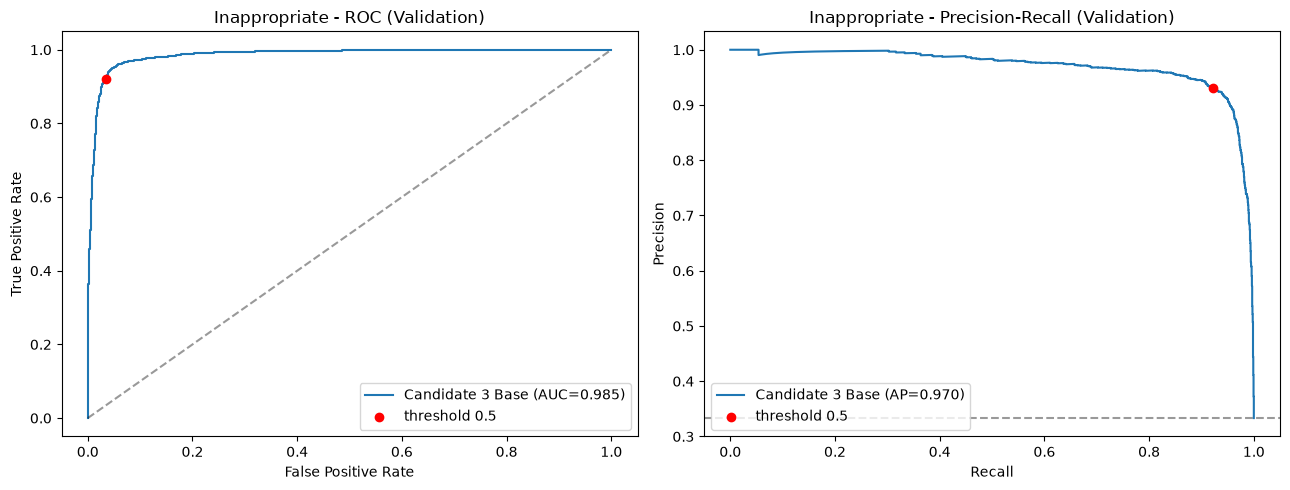

In [21]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

y_val = inappropriate_val["label"].values

fpr, tpr, roc_thr = roc_curve(y_val, inapp_cnd_base_prob)
prec, rec, pr_thr = precision_recall_curve(y_val, inapp_cnd_base_prob)

# Where the default 0.5 threshold sits on the curves
pred_05 = inapp_cnd_base_prob >= 0.5
fpr_05 = (pred_05 & (y_val == 0)).sum() / (y_val == 0).sum()
tpr_05 = (pred_05 & (y_val == 1)).sum() / (y_val == 1).sum()
prec_05 = (pred_05 & (y_val == 1)).sum() / max(pred_05.sum(), 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(fpr, tpr, label=f"Candidate 3 Base (AUC={roc_auc_score(y_val, inapp_cnd_base_prob):.3f})")
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax1.scatter([fpr_05], [tpr_05], color="red", zorder=3, label="threshold 0.5")
ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Inappropriate - ROC (Validation)")
ax1.legend(loc="lower right")

ax2.plot(rec, prec, label=f"Candidate 3 Base (AP={average_precision_score(y_val, inapp_cnd_base_prob):.3f})")
ax2.axhline(y_val.mean(), color="k", ls="--", alpha=0.4)
ax2.scatter([tpr_05], [prec_05], color="red", zorder=3, label="threshold 0.5")
ax2.set(xlabel="Recall", ylabel="Precision", title="Inappropriate - Precision-Recall (Validation)")
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

## Threshold Selection (Validation)

In [39]:
def threshold_at_fpr(y_true, probs, max_fpr):
    # Highest recall while the false positive rate stays at or below max_fpr
    fpr, tpr, thr = roc_curve(y_true, probs)
    i = np.where(fpr <= max_fpr)[0][-1]
    return thr[i]


def threshold_summary(y_true, probs, thresholds):
    rows = []
    for name, t in thresholds.items():
        pred = probs >= t
        rows.append({
            "rule": name,
            "threshold": t,
            "recall (TPR)": (pred & (y_true == 1)).sum() / (y_true == 1).sum(),
            "false positive rate": (pred & (y_true == 0)).sum() / (y_true == 0).sum(),
            "precision": (pred & (y_true == 1)).sum() / max(pred.sum(), 1),
            "flagged %": pred.mean() * 100
        })
    return pd.DataFrame(rows)


# Best-F1 point from the precision-recall curve
f1_curve = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)

candidate_thresholds = {
    "default 0.5": 0.5,
    "max recall, FPR <= 0.5%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.005),
    "max recall, FPR <= 1%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.01),
    "max recall, FPR <= 2%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.02),
    "max recall, FPR <= 3%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.03),
    "max recall, FPR <= 4%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.04),
    "max recall, FPR <= 5%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.05),
    "max recall, FPR <= 10%": threshold_at_fpr(y_val, inapp_cnd_base_prob, 0.10),
    "best F1": pr_thr[np.argmax(f1_curve)]
}

display(threshold_summary(y_val, inapp_cnd_base_prob, candidate_thresholds))

# Pick the rule that fits the product, then use that value below
inapp_threshold = candidate_thresholds["max recall, FPR <= 3%"]
print("Chosen inappropriate threshold:", inapp_threshold)

,rule,threshold,recall (TPR),false positive rate,precision,flagged %
0,default 0.5,0.500000,0.921425,0.034049,0.931181,32.984110
1,"max recall, FPR <= 0.5%",0.924293,0.511262,0.004976,0.980905,17.373843
2,"max recall, FPR <= 1%",0.863853,0.682032,0.009953,0.971642,23.397940
3,"max recall, FPR <= 2%",0.736995,0.851755,0.019906,0.955347,29.718876
4,"max recall, FPR <= 3%",0.555485,0.910424,0.029859,0.938445,32.338048
5,"max recall, FPR <= 4%",0.433979,0.939235,0.039550,0.922325,33.944474
6,"max recall, FPR <= 5%",0.358493,0.952331,0.049764,0.905378,35.061987
7,"max recall, FPR <= 10%",0.208009,0.972761,0.095076,0.836486,38.763751
8,best F1,0.433979,0.939235,0.039550,0.922325,33.944474


Chosen inappropriate threshold: 0.5554849417718852


## Candidate Ensemble Test Result at Chosen Threshold

In [40]:
inapp_cnd_base_tuned_test_results = evaluate_binary(
    inappropriate_test["label"].values,
    inapp_cnd_base_test_prob,
    threshold=inapp_threshold,
    model_name=("Inappropriate Candidate Ensemble (3 Base Models) (Test, tuned threshold)")
)


Inappropriate Candidate Ensemble (3 Base Models) (Test, tuned threshold)
{'model': 'Inappropriate Candidate Ensemble (3 Base Models) (Test, tuned threshold)', 'accuracy': 0.973180353602115, 'precision': 0.20455254131587153, 'recall': 0.9344729344729344, 'f1': 0.33563571245842927, 'roc_auc': 0.9879695497816792}
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     96130
           1       0.20      0.93      0.34       702

    accuracy                           0.97     96832
   macro avg       0.60      0.95      0.66     96832
weighted avg       0.99      0.97      0.98     96832

Confusion matrix:
 [[93579  2551]
 [   46   656]]
